# Predicting Flight Delays – Data Exploration

**What is this notebook about?**
Our exam project asks: *Can we predict if a Delta flight will arrive 15 minutes or more late, using only information we know before the flight leaves?*

Before we can build a model, we need to **know our data**. That is what this notebook does.

**The main idea (from Week 2):** before you clean your data, first find the problems. If you clean too fast, you might delete data that was actually correct. So in this notebook we only **look** at the data. We do not change anything yet.

**The plan:**
1. Load the data
2. Check the size and the types of data
3. Check 1 – Does each column look normal on its own?
4. Check 2 – Do the columns make sense together?
5. Check 3 – Does the data follow the rules?
6. Check 4 – What is missing, and why?
7. Summary – a to-do list for cleaning

## Step 1: Load the data

**What we do:** We open the data file, so Python can work with it.

**The data:** Flights in the USA in January 2025, downloaded from BTS (the US Bureau of Transportation Statistics). Each row is one flight.

**The tools we use:**
- **pandas** (`pd`): a library for working with tables. It turns the CSV file into a table called a *dataframe* (`df`).
- **matplotlib** (`plt`): a library for drawing charts.

In [1]:
# load pandas, the library for working with tables. We call it pd for short
import pandas as pd

In [2]:
# load matplotlib, the library for drawing charts. We call it plt for short
import matplotlib.pyplot as plt

In [3]:
# read the CSV file and save it as a table called df (short for dataframe)
df = pd.read_csv('January_2025.csv')

In [4]:
# show the first 5 rows, to check that the file was read in correctly
df.head(5)

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025,1,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,500,754,0.0,0.0,0.0,114.0,569.0
1,2025,1,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,555,849,0.0,0.0,0.0,114.0,569.0
2,2025,1,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,820,1114,0.0,0.0,0.0,114.0,569.0
3,2025,1,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1032,1323,0.0,0.0,0.0,111.0,569.0
4,2025,1,1,1,3,1/1/2025 12:00:00 AM,AA,ABQ,DFW,1700,1948,1.0,0.0,0.0,108.0,569.0


## Step 2: Size and data types

**What we do:** We check how big the table is, and what kind of data each column holds.

**Why:** We need to know what we are working with. Are the columns numbers or text? And are there any empty cells?

**The code:**
- `df.shape` shows (number of rows, number of columns).
- `df.info()` shows each column's name, how many cells are filled in (*Non-Null Count*) and the data type (*Dtype*).
  - `int64` and `float64` = numbers
  - `str` = text

In [5]:
# number of rows (flights) and columns
df.shape

(539747, 16)

In [6]:
# column names, how many cells are filled in, and the data type of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   YEAR               539747 non-null  int64  
 1   QUARTER            539747 non-null  int64  
 2   MONTH              539747 non-null  int64  
 3   DAY_OF_MONTH       539747 non-null  int64  
 4   DAY_OF_WEEK        539747 non-null  int64  
 5   FL_DATE            539747 non-null  str    
 6   OP_UNIQUE_CARRIER  539747 non-null  str    
 7   ORIGIN             539747 non-null  str    
 8   DEST               539747 non-null  str    
 9   CRS_DEP_TIME       539747 non-null  int64  
 10  CRS_ARR_TIME       539747 non-null  int64  
 11  ARR_DEL15          522269 non-null  float64
 12  CANCELLED          539747 non-null  float64
 13  DIVERTED           539747 non-null  float64
 14  CRS_ELAPSED_TIME   539747 non-null  float64
 15  DISTANCE           539747 non-null  float64
dtypes: float64(5)

**Findings (size and data types):**
- We have **539,747 flights** and **16 columns**.
- Most columns are **numbers**, for example times, distance, day and month.
- Four columns are **text**: the date (FL_DATE), the airline, the origin airport and the destination airport.
- **Only ARR_DEL15 (our target) has empty cells.** How do we see that? All other columns have 539,747 filled-in cells, but ARR_DEL15 only has 522,269. So **17,478 cells are empty**. We look into why in Check 4.

## Step 3: Check 1 – Does each column look normal on its own?
*(Univariate analysis)*

**What we do:** We look at one column at a time, and ask: does any value look impossible or strange?

**Why:** A strange value can be an error, for example a flight with a distance of 0 miles. But a strange value is not always wrong, so we only look now and do not delete anything.

**How:** The table is too big to read row by row, so we use:
- `describe()`: the smallest, largest and average value of every number column at once
- **histograms**: a chart that shows how the values are spread out
- `value_counts()`: counts how many times each value appears (good for text columns)

In [7]:
# summary of all number columns:
# count = filled-in cells, mean = average, min = smallest, max = largest
df.describe()

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
count,539747.0,539747.0,539747.0,539747.000000,539747.000000,539747.000000,539747.000000,522269.000000,539747.000000,539747.000000,539747.000000,539747.000000
mean,2025.0,1.0,1.0,15.831995,4.019748,1315.739317,1502.662084,0.187892,0.030222,0.002160,151.410600,843.208216
std,0.0,0.0,0.0,9.036782,1.925782,480.555061,502.478468,0.390626,0.171197,0.046429,73.812226,599.092323
min,2025.0,1.0,1.0,1.000000,1.000000,5.000000,1.000000,0.000000,0.000000,0.000000,25.000000,31.000000
25%,2025.0,1.0,1.0,8.000000,2.000000,905.000000,1117.000000,0.000000,0.000000,0.000000,96.000000,403.000000
50%,2025.0,1.0,1.0,16.000000,4.000000,1310.000000,1524.000000,0.000000,0.000000,0.000000,135.000000,701.000000
75%,2025.0,1.0,1.0,24.000000,6.000000,1725.000000,1924.000000,0.000000,0.000000,0.000000,183.000000,1083.000000
max,2025.0,1.0,1.0,31.000000,7.000000,2359.000000,2359.000000,1.000000,1.000000,1.000000,693.000000,5095.000000


**Findings (Check 1 – describe):**
We looked at the smallest and largest value in each column, and **all values look realistic**. Nothing is impossible.
- **Date:** all flights are from January 2025 (YEAR is always 2025, MONTH is always 1).
- **Times:** departure and arrival times are between 00:01 and 23:59, which are normal clock times.
- **Distance:** from 31 to 5,095 miles. No flights with 0 miles.
- **Flight time:** from 25 to 693 minutes. No flights with 0 minutes.
- **Our target (ARR_DEL15):** the average is 0.188. Since the column is only 0 (on time) or 1 (late), this means **18.8% of the flights are late**.
- **CANCELLED:** the average is 0.03, so **3% of the flights were cancelled**.

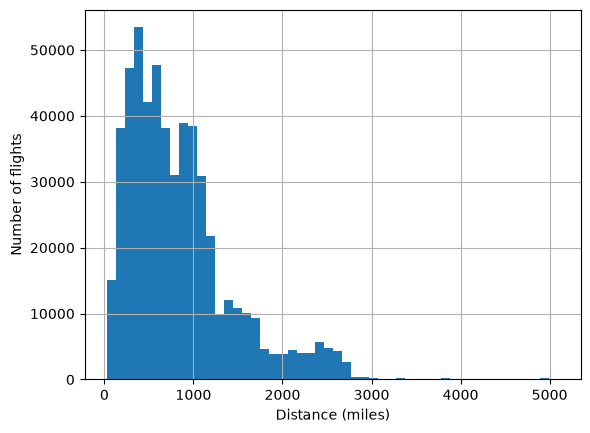

In [8]:
# histogram of flight distance
# each bar shows how many flights have a distance in that range
df["DISTANCE"].hist(bins=50)
plt.xlabel("Distance (miles)")
plt.ylabel("Number of flights")
plt.show()

**Findings (distance):**
- Most flights are **short**, between about 200 and 1,200 miles.
- Fewer flights are long (2,000–2,700 miles), for example from coast to coast.
- A very small number go up to about 5,000 miles. These are probably flights to Hawaii.
- There are **no impossible values**, like 0 or negative distances.

So the column looks normal.

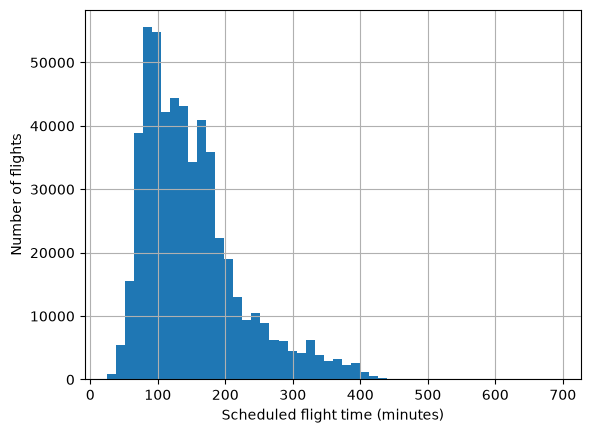

In [9]:
# histogram of scheduled flight time (in minutes)
# each bar shows how many flights are planned to take that long
df["CRS_ELAPSED_TIME"].hist(bins=50)
plt.xlabel("Scheduled flight time (minutes)")
plt.ylabel("Number of flights")
plt.show()

**Findings (flight time):**
- Most flights are planned to take between **1 and 3 hours**.
- Fewer flights take 4–7 hours, and a very small number take up to about 11 hours (probably flights to Hawaii).
- The shortest flights take around 25 minutes.
- There are **no impossible values**, like 0 or negative flight times.

So the column looks normal.

In [10]:
# count the number of flights for each airline (biggest first)
df["OP_UNIQUE_CARRIER"].value_counts()

OP_UNIQUE_CARRIER
WN    105307
DL     76306
AA     75088
OO     65036
UA     62007
YX     27833
MQ     21890
OH     21094
AS     18163
B6     17918
NK     17544
F9     15526
G4      9345
HA      6690
Name: count, dtype: int64

**Findings (airlines):**
- There are **14 airlines** in the data.
- Southwest (WN) has the most flights, and **Delta (DL) is second with 76,306 flights**.
- This is good for our project: we have a lot of Delta flights to learn from.

In [11]:
# the 10 airports with the most departures
df["ORIGIN"].value_counts().head(10)

ORIGIN
DFW    25124
DEN    24732
ATL    23881
ORD    21643
CLT    16877
PHX    15956
LAX    15157
LAS    15007
MCO    13058
SEA    11882
Name: count, dtype: int64

**Findings (airports):**
- Most flights leave from big airports like Dallas (DFW), Denver (DEN) and Atlanta (ATL).
- Atlanta is Delta's home airport, so many of our Delta flights will probably start there.

In [12]:
# share of on-time (0) and late (1) flights
# normalize=True gives the share (0.81 = 81%) instead of the count
df["ARR_DEL15"].value_counts(normalize=True)

ARR_DEL15
0.0    0.812108
1.0    0.187892
Name: proportion, dtype: float64

**Findings (target – late or on time):**
- **81% of the flights are on time**, and **19% are late**.
- So most flights are not late. This is called **unbalanced data**.

**Why does this matter?**
- The model sees many more on-time flights than late flights. So it gets better at recognising on-time flights, and may guess "on time" too often.
- A "lazy" model that always says "on time" would be right 81% of the time, without learning anything. So **accuracy alone can trick us**.
- That is why we later use **precision, recall and F1**, which show how good the model is at finding the *late* flights.

## Step 4: Check 2 – Do the columns make sense together?
*(Bivariate analysis)*

**What we do:** We look at two columns at the same time.

**Why:** Some problems only show up when you look at two columns together. For example, 3,000 miles is fine, and 30 minutes is fine. But a flight of 3,000 miles that takes only 30 minutes is impossible.

**What we check:**
1. Do **distance** and **flight time** fit together? (A scatterplot and a correlation)
2. Are there any strange flights? (Long distance but very short time)
3. Are some **days** or **airlines** late more often than others?

We draw the scatterplot with a random sample of 10,000 flights, because 539,747 dots would be slow and hard to read.

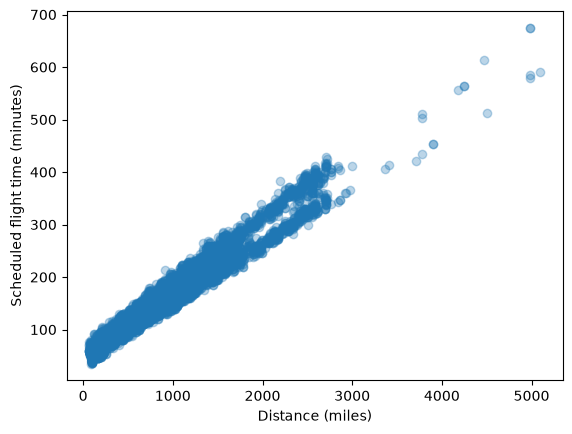

In [13]:
# pick 10,000 random flights (random_state=1 gives the same sample every time)
# then draw one dot per flight: distance along the bottom, flight time up the side
# alpha=0.3 makes the dots a bit see-through, so we can see where there are many
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Distance (miles)")
plt.ylabel("Scheduled flight time (minutes)")
plt.show()

In [14]:
# correlation = one number for how strongly two columns go together
# 1 = perfect, 0 = no connection
df[["DISTANCE", "CRS_ELAPSED_TIME"]].corr()

,DISTANCE,CRS_ELAPSED_TIME
DISTANCE,1.000000,0.977863
CRS_ELAPSED_TIME,0.977863,1.000000


In [15]:
# look for strange flights: over 1,500 miles but under 60 minutes
# if the table is empty, there are no strange flights
df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]

,YEAR,QUARTER,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE


In [16]:
# share of late flights for each day of the week (1 = Monday, 7 = Sunday)
# 0.22 means 22% of the flights that day were late
df.groupby("DAY_OF_WEEK")["ARR_DEL15"].mean()

DAY_OF_WEEK
1    0.226388
2    0.153129
3    0.132801
4    0.173680
5    0.194624
6    0.216392
7    0.225945
Name: ARR_DEL15, dtype: float64

In [17]:
# share of late flights for each airline, highest first
df.groupby("OP_UNIQUE_CARRIER")["ARR_DEL15"].mean().sort_values(ascending=False)

OP_UNIQUE_CARRIER
F9    0.259762
OH    0.254817
B6    0.244561
G4    0.237128
OO    0.208828
DL    0.193205
AA    0.192281
MQ    0.184293
NK    0.180810
UA    0.176271
AS    0.175772
YX    0.160177
WN    0.152086
HA    0.135474
Name: ARR_DEL15, dtype: float64

**Findings (Check 2):**

**Distance and flight time:**
- In the scatterplot, the dots form an **almost straight line going up**. So the longer the distance, the longer the planned flight time. That makes sense.
- The correlation is **0.98**, which is very close to 1 (perfect). So the two columns fit well together.
- We searched for strange flights (over 1,500 miles but under 60 minutes), and the table was **empty**. So there are **no strange flights**.

**Days of the week:**
- **Monday and Sunday** have the most late flights (about 23%).
- **Wednesday** has the fewest (13%).
- So the day of the week seems to matter. That makes it a useful input for the model.

**Airlines:**
- **Frontier (F9)** is late most often (26%), and **Hawaiian (HA)** least often (14%).
- **Delta (DL)** is close to the average, with 19%.
- So the airline seems to matter too.

## Step 5: Check 3 – Does the data follow the rules?
*(Constraint and rule checking)*

**What we do:** We write down rules that must always be true, and let the computer test them on every flight.

**How we found the rules:** For each column, we asked: *"What would be impossible here?"*
- **Calendar and clock:** a week has 7 days, a month has at most 31 days, and we only downloaded January. A clock goes from 00:00 to 23:59.
- **Flights:** a flight must have a distance and a flight time above 0, and it cannot fly to the same airport it left from.
- **Yes/no columns:** ARR_DEL15, CANCELLED and DIVERTED can only be 0 (no) or 1 (yes).

**How to read the result:** `True` means the rule holds for **all** flights. `False` means at least one flight breaks it.

Note: `CRS_DEP_TIME` is written as hhmm, so 555 = 05:55 and 1430 = 14:30. The last two digits are the minutes, so they must be under 60.

In [18]:
# a list of rules. Each rule is tested on all flights:
# True = all flights follow the rule, False = some flights break it
# .between(1, 7) checks that a value is from 1 to 7
# .isin([0, 1]) checks that a value is either 0 or 1
# .all() checks that this is true for ALL flights
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "MONTH is always 1 (January)": (df["MONTH"] == 1).all(),
    "DAY_OF_WEEK is 1-7": df["DAY_OF_WEEK"].between(1, 7).all(),
    "DAY_OF_MONTH is 1-31": df["DAY_OF_MONTH"].between(1, 31).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - MONTH is always 1 (January)
True - DAY_OF_WEEK is 1-7
True - DAY_OF_MONTH is 1-31
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different


**Findings (Check 3):**
- **All rules hold** (everything is True).
- The days, months and times are all possible.
- All flights have a distance and a flight time above 0.
- No flight goes to the same airport it left from.
- The yes/no columns only contain 0 and 1.

So we found **no impossible values** in the data.

## Step 6: Check 4 – What is missing, and why?
*(Missingness analysis)*

**What we do:** We do two things:
1. **Count** how many cells are empty in each column.
2. Look at **who** is missing. Are the empty cells spread out randomly, or are they all in one group?

**Why:** Before we can decide what to do with empty cells, we need to know **why** they are empty. There are three types:
- **MCAR:** no pattern. The empty cells are random (bad luck).
- **MAR:** there is a pattern, and we can see it in another column.
- **MNAR:** there is a pattern, but we can't see it, because the missing value itself is the reason.

In [19]:
# count the empty cells in each column
df.isna().sum()

YEAR                     0
QUARTER                  0
MONTH                    0
DAY_OF_MONTH             0
DAY_OF_WEEK              0
FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            17478
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

In [20]:
# share of empty cells in each column (0.03 = 3%)
df.isna().mean()

YEAR                 0.000000
QUARTER              0.000000
MONTH                0.000000
DAY_OF_MONTH         0.000000
DAY_OF_WEEK          0.000000
FL_DATE              0.000000
OP_UNIQUE_CARRIER    0.000000
ORIGIN               0.000000
DEST                 0.000000
CRS_DEP_TIME         0.000000
CRS_ARR_TIME         0.000000
ARR_DEL15            0.032382
CANCELLED            0.000000
DIVERTED             0.000000
CRS_ELAPSED_TIME     0.000000
DISTANCE             0.000000
dtype: float64

In [21]:
# take only the flights with an empty target
# and count how many of them were cancelled or diverted
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", missing["CANCELLED"].sum())
print("Of these, diverted:", missing["DIVERTED"].sum())

Flights with empty target: 17478
Of these, cancelled: 16312.0
Of these, diverted: 1166.0


In [22]:
# share of flights with an empty target for each airline, highest first
# this shows if one airline is missing more than the others (is there a pattern?)
df["ARR_DEL15"].isna().groupby(df["OP_UNIQUE_CARRIER"]).mean().sort_values(ascending=False)

OP_UNIQUE_CARRIER
OH    0.092112
MQ    0.048378
YX    0.041318
AA    0.040033
NK    0.034086
WN    0.030264
DL    0.029893
F9    0.026794
OO    0.023587
HA    0.022422
UA    0.021594
B6    0.020092
AS    0.017398
G4    0.014874
Name: ARR_DEL15, dtype: float64

**Findings (Check 4):**

**How much is missing?**
- Only ARR_DEL15 has empty cells: **17,478 flights, about 3%**.

**Who is missing?**
- 16,312 of these flights were **cancelled**, and 1,166 were **diverted** (they landed at a different airport).
- 16,312 + 1,166 = 17,478. So **every** empty cell is a cancelled or diverted flight.
- This makes sense: these flights never arrived at their planned airport, so they can't be "late" or "on time".
- Per airline, OH misses the most (9%), while most airlines only miss 2–4%. This is because OH cancelled more flights.

**Which type of missing is it?**
- It is **MAR**: there is a pattern, and we can see it in other columns (CANCELLED and DIVERTED explain every empty cell).
- It is **not MCAR**, because the empty cells are not random.

**What should we do with them?**
- **Fill in the average (imputation)?** No. The average of ARR_DEL15 is 0.19, but a flight can't be "0.19 late". And we would be inventing an arrival that never happened.
- **Set them to late (1) or on time (0)?** No. A cancelled flight was not late, it did not fly at all. The model would learn from wrong answers.
- **Remove them?** Yes. It is only 3% of the flights, so we still have about 522,000 flights. And our question is about flights that *arrive*, so these flights don't fit our question anyway.

**Decision:** We will remove the cancelled and diverted flights in the cleaning step. We do not remove them now, because in this notebook we only look at the data.

**Limitation:** Because we remove these flights, our model can't say anything about cancellations. It only predicts delays for flights that arrive. We should mention this in the report.

## Step 7: Summary – what we found

**Overall:** The data looks good. All values are realistic, the columns fit together, and all rules hold. The only real problem is the empty target for cancelled and diverted flights.

**To-do list for the cleaning step** (we don't change the data yet):

| Problem | Column | What we will do when cleaning |
|---|---|---|
| Empty target for cancelled/diverted flights | ARR_DEL15 | Remove these flights and explain why in the report |
| Same value in every row (only January 2025) | YEAR, QUARTER, MONTH | Remove. They give the model no information |
| Only 0 after removing cancelled/diverted flights | CANCELLED, DIVERTED | Remove after the step above |
| The date is written twice | FL_DATE | Remove. We already have DAY_OF_MONTH and DAY_OF_WEEK |
| Unbalanced target (81% on time, 19% late) | ARR_DEL15 | Don't change the data, but judge the model with precision, recall and F1, not only accuracy |